1/clkgen_freq=125.0 ns phase_shift_steps=4200
ext_offset=3 (375 ns)  offset=0 (0 ps)  width=3360 (100 ns)  repeat=1 (pulse 100 ns)
computed start=865 ns   measured: delay=1075 ns  pulse=25 ns  start diff=210 ns


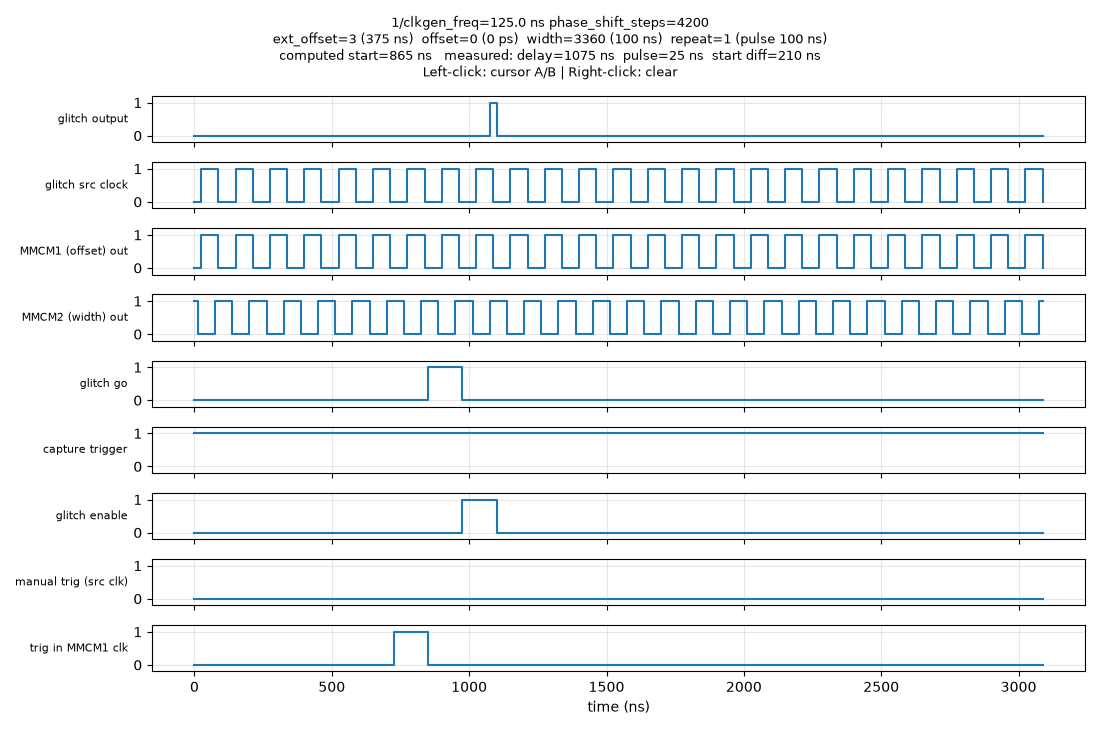

scope.glitch.clk_src  pll
scope.clock.clkgen_freq  8000000.0
scope.clock.fpga_vco_freq  600000000.0
scope.LA.sampling_clock_frequency  80001251.22070312
scope.LA.downsample  1
scope.glitch.phase_shift_steps  4200
ext_offset=1      pulses=1  delay=     728 ns  pulse=     126 ns
ext_offset=5      pulses=1  delay=    1225 ns  pulse=     125 ns
ext_offset=20     pulses=1  delay=    3163 ns  pulse=     126 ns
ext_offset=100    pulses=0  delay=     nan ns  pulse=     nan ns


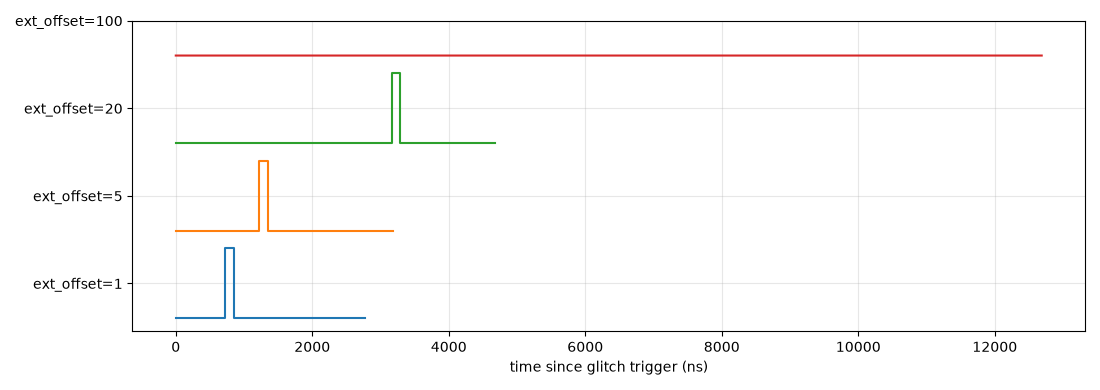

In [44]:
%run "./LibLogicAnalyserGlitchTools.ipynb"

import chipwhisperer as cw

try:
    scope.dis()
except:
    pass

scope = cw.scope()
scope.default_setup(verbose=False)
scope.clock.clkgen_freq = 8e6

#sweep(scope, "ext_offset", [1, 5, 20, 100])          # delay should grow ~100 ns per count
#sweep(scope, "repeat", [1, 2, 5, 10], ext_offset=5)  # pulse length in clock cycles
# one run with all 9 channels, using the interactive plot
ext_offset = 3
width = 3360
offset = 0
repeat = 1
#output="enable_only"  # one large glitch repeat times
output="glitch_only" # multiple short (width) glitches
res = run_glitch(scope, ext_offset=ext_offset, width=width, repeat=repeat, offset=offset, output=output, f_glitch=scope.clock.clkgen_freq)

print(caption(res))
fig = plot_la_interactive(res["t"] * 1e9, res["sigs"], LA_NAMES["glitch"], unit="ns", title=caption(res))

print("scope.glitch.clk_src ", scope.glitch.clk_src)
print("scope.clock.clkgen_freq ", scope.clock.clkgen_freq)
print("scope.clock.fpga_vco_freq ", scope.clock.fpga_vco_freq)
print("scope.LA.sampling_clock_frequency ", scope.LA.sampling_clock_frequency)
print("scope.LA.downsample ", scope.LA.downsample)
print("scope.glitch.phase_shift_steps ", scope.glitch.phase_shift_steps)
sweep(scope, "ext_offset", [1, 5, 20, 100])   # ns per count = real period on the plot axis

scope.dis()
scope=None